# Experiment 19: Naive Bayes for Bank Loan Prediction
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement **Naive Bayes classification for Bank Loan prediction** (loan approved: Yes / No).

## Note on the data
A **synthetic bank-loan data set** (applicant income, age, loan amount, credit history, employment, education, property area, dependents) is generated with a fixed seed. For a real data set (e.g. Kaggle *Loan Prediction*) replace the data cell with `df = pd.read_csv('loan.csv')` and keep the column names or adjust the lists below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(3)
n = 1500
df = pd.DataFrame({
    'Age': rng.integers(21, 65, n),
    'Applicant_Income': rng.normal(5500, 2500, n).clip(1500, 20000).round(),
    'Loan_Amount': rng.normal(140, 60, n).clip(20, 400).round(),          # in thousands
    'Credit_History': rng.choice(['Good', 'Bad'], n, p=[0.8, 0.2]),
    'Employment': rng.choice(['Salaried', 'Self-employed', 'Unemployed'], n, p=[0.6, 0.3, 0.1]),
    'Education': rng.choice(['Graduate', 'Not Graduate'], n, p=[0.75, 0.25]),
    'Property_Area': rng.choice(['Urban', 'Semiurban', 'Rural'], n),
    'Dependents': rng.integers(0, 4, n),
})
z = (2.2 * (df.Credit_History == 'Good') + 0.0004 * df.Applicant_Income - 0.008 * df.Loan_Amount
     + 0.4 * (df.Education == 'Graduate') - 1.2 * (df.Employment == 'Unemployed')
     + 0.3 * (df.Property_Area == 'Semiurban') - 0.15 * df.Dependents - 0.2 + rng.normal(0, 0.25, n))
df['Loan_Approved'] = np.where(z > np.quantile(z, 0.30), 'Yes', 'No')   # ~70 % approved
df.to_csv('bank_loan_synthetic.csv', index=False)
print(df.shape); print(df['Loan_Approved'].value_counts())
df.head()

(1500, 9)
Loan_Approved
Yes    1050
No      450
Name: count, dtype: int64


,Age,Applicant_Income,Loan_Amount,Credit_History,Employment,Education,Property_Area,Dependents,Loan_Approved
0,56,3791.0,39.0,Good,Self-employed,Graduate,Semiurban,3,Yes
1,24,5428.0,102.0,Good,Self-employed,Graduate,Urban,1,Yes
2,28,4469.0,328.0,Good,Self-employed,Graduate,Semiurban,1,No
3,31,6670.0,113.0,Good,Self-employed,Not Graduate,Urban,0,Yes
4,28,7810.0,183.0,Good,Self-employed,Not Graduate,Urban,0,Yes


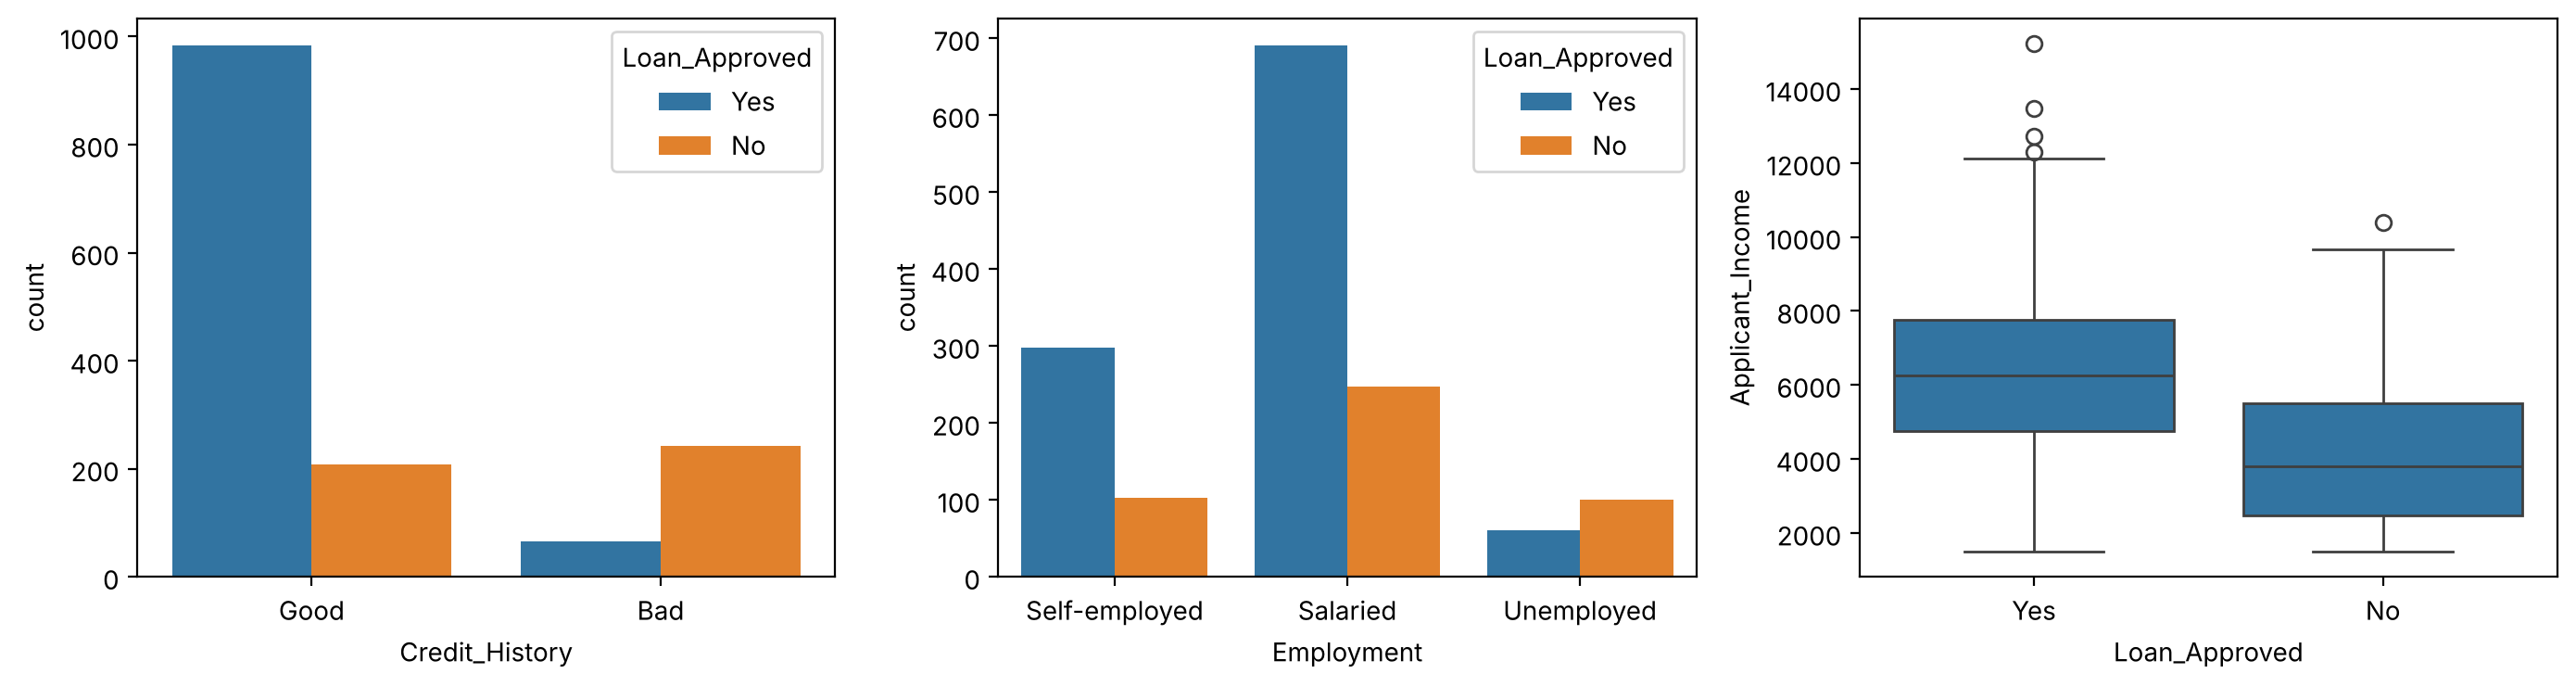

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.countplot(data=df, x='Credit_History', hue='Loan_Approved', ax=ax[0])
sns.countplot(data=df, x='Employment', hue='Loan_Approved', ax=ax[1])
sns.boxplot(data=df, x='Loan_Approved', y='Applicant_Income', ax=ax[2])
plt.tight_layout(); plt.show()

Accuracy: 0.83 

              precision    recall  f1-score   support

          No       0.75      0.64      0.69        90
         Yes       0.86      0.91      0.88       210

    accuracy                           0.83       300
   macro avg       0.80      0.78      0.79       300
weighted avg       0.83      0.83      0.83       300



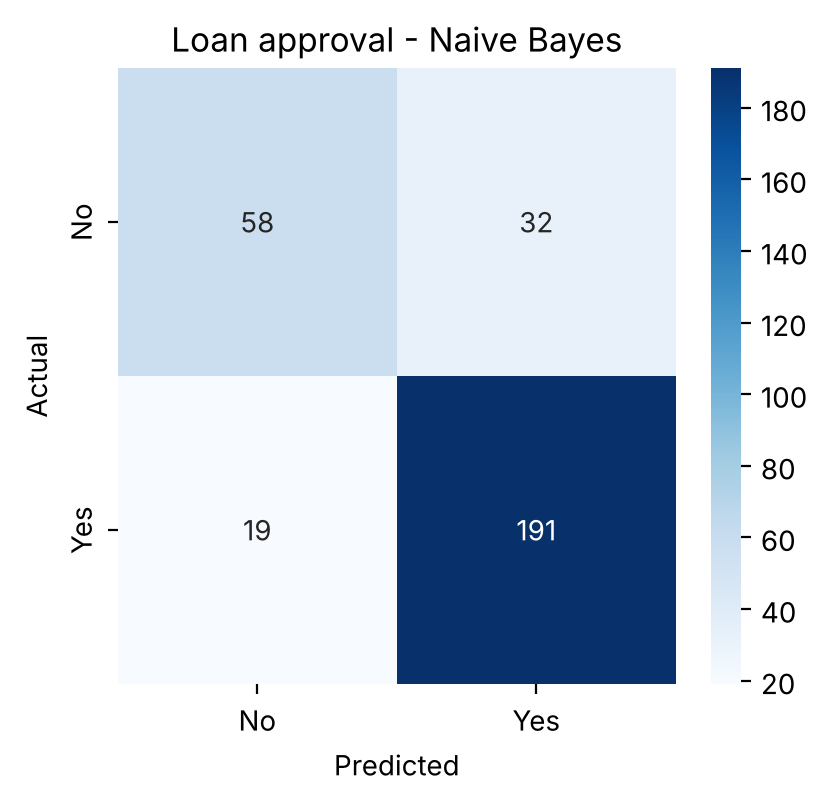

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

X, y = df.drop(columns='Loan_Approved'), df['Loan_Approved']
cat = ['Credit_History', 'Employment', 'Education', 'Property_Area']
num = ['Age', 'Applicant_Income', 'Loan_Amount', 'Dependents']
prep = ColumnTransformer([('cat', OneHotEncoder(sparse_output=False), cat), ('num', 'passthrough', num)])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = Pipeline([('prep', prep), ('nb', GaussianNB())]).fit(X_train, y_train)
pred = model.predict(X_test)

print('Accuracy:', round(accuracy_score(y_test, pred), 4), '\n')
print(classification_report(y_test, pred))
plt.figure(figsize=(4.5, 4))
sns.heatmap(confusion_matrix(y_test, pred, labels=['No', 'Yes']), annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Loan approval - Naive Bayes'); plt.show()

In [4]:
applicants = pd.DataFrame([
    {'Age': 34, 'Applicant_Income': 7500, 'Loan_Amount': 120, 'Credit_History': 'Good',
     'Employment': 'Salaried', 'Education': 'Graduate', 'Property_Area': 'Urban', 'Dependents': 1},
    {'Age': 45, 'Applicant_Income': 2500, 'Loan_Amount': 250, 'Credit_History': 'Bad',
     'Employment': 'Unemployed', 'Education': 'Not Graduate', 'Property_Area': 'Rural', 'Dependents': 3},
])
probs = model.predict_proba(applicants)
for i, (p, c) in enumerate(zip(model.predict(applicants), probs), 1):
    print(f'Applicant {i}: loan {"APPROVED" if p == "Yes" else "REJECTED"} '
          f'(P(No)={c[0]:.3f}, P(Yes)={c[1]:.3f})')

Applicant 1: loan APPROVED (P(No)=0.003, P(Yes)=0.997)
Applicant 2: loan REJECTED (P(No)=1.000, P(Yes)=0.000)


## Result
Naive Bayes predicts loan approval from applicant details with about 83 % accuracy (it finds about 91 % of the approvable applicants and about 64 % of the rejectable ones). The exploratory plots show that credit history, employment status and income separate approved from rejected applications, and the model's probabilities can be used for decision support.